# 01 · Preprocessing — Zhang et al. 2021 (Kidney, Renal Cell Carcinoma, 10x)

Load malignant cells → derive per-sample threshold → HVG → PCA → **Harmony on `sample` with a theta sweep** → neighbours/UMAP → **Gate 1** judged on the regenerated embedding + per-neighbourhood iLISI (not a scalar) → complete island removal → annotate states from data markers + the publication's meta-programs.

This is a 4th-attempt re-run of a prior science failure; every tunable choice is **derived from this dataset and shown here**.

In [ ]:
import os, sys, glob, warnings, contextlib, io
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
import scipy.sparse as sp
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components
import logging
for lg in ['harmonypy']:
    logging.getLogger(lg).setLevel(logging.ERROR); logging.getLogger(lg).disabled=True
sc.settings.verbosity = 0
SEED = 1; np.random.seed(SEED)

In [ ]:
# --- paths: notebook lives at Claude/<Category>/<Dataset>-3, two levels below Puram ---
name = os.path.basename(os.getcwd())              # Zhang2021_Kidney-3
cat  = os.path.basename(os.path.dirname(os.getcwd()))  # Kidney
JOINKEY = 'Data_Zhang2021_Kidney'                 # on-disk input folder (no -3 suffix)
pth      = os.path.join(*([os.pardir]*4))         # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', JOINKEY)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_cb   = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
sys.path.append(os.path.join(pth, 'mesencontext', 'scripts'))
from load import load_CCCA_adata
CITE = 'Zhang et al., 2021'
print('name', name, '| cat', cat)

name Zhang2021_Kidney-3 | cat Kidney


### Load malignant cells

In [ ]:
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
malignant_raw = adata.n_obs
print('malignant cells (raw):', malignant_raw, '| genes:', adata.n_vars)
print('samples:', adata.obs["sample"].nunique(), '| disease:', dict(adata.obs.disease.value_counts()))

Loading ../../../../../../data/unzip/CCCA/Data_Zhang2021_Kidney
Done.
malignant cells (raw): 11410 | genes: 33694
samples: 8 | disease: {'Clear_Cell_RCC': np.int64(9139), 'Chromophobe_RCC': np.int64(2271)}


### Per-sample threshold — derived from the count distribution (C1/C2)
Sort per-sample malignant counts, find the **dominant multiplicative gap**, cut at its geometric mean. No hard-coded ≥100 constant.

In [ ]:
n = adata.obs['sample'].value_counts()
s = np.sort(n.values)
ratios = s[1:] / s[:-1]
gi = int(np.argmax(ratios)); lo, hi = s[gi], s[gi+1]
cut = float(np.sqrt(lo*hi))
print('per-sample counts:', n.to_dict())
print('sorted:', s.tolist())
print('adjacent ratios:', np.round(ratios,2).tolist())
print(f'dominant gap {lo}->{hi} (ratio {hi/lo:.2f}); geometric-mean cut = {cut:.0f}')
keep = n.index[n >= cut]
adata = adata[adata.obs['sample'].isin(keep)].copy()
after_threshold = adata.n_obs
print(f'kept {len(keep)}/{len(n)} samples; cells after threshold = {after_threshold} (dropped {malignant_raw-after_threshold})')
print('disease x kept sample:')
print(adata.obs.groupby("sample",observed=True).disease.agg(lambda x: x.value_counts().index[0]).to_dict())

per-sample counts: {'SI_23459': 3443, 'SI_21561': 2271, 'SI_19703': 1409, 'SI_22604': 1209, 'SI_23843': 1184, 'SI_18854': 992, 'SI_22368': 710, 'SI_18855': 192}
sorted: [192, 710, 992, 1184, 1209, 1409, 2271, 3443]
adjacent ratios: [3.7, 1.4, 1.19, 1.02, 1.17, 1.61, 1.52]
dominant gap 192->710 (ratio 3.70); geometric-mean cut = 369
kept 7/8 samples; cells after threshold = 11218 (dropped 192)
disease x kept sample:
{'SI_18854': 'Clear_Cell_RCC', 'SI_19703': 'Clear_Cell_RCC', 'SI_21561': 'Chromophobe_RCC', 'SI_22368': 'Clear_Cell_RCC', 'SI_22604': 'Clear_Cell_RCC', 'SI_23459': 'Clear_Cell_RCC', 'SI_23843': 'Clear_Cell_RCC'}


**Note:** one Chromophobe-RCC sample (SI_21561) mixes with six Clear-Cell-RCC samples. Whether this is a distinct lobe or one continuous population is the central Gate-1 question, settled below on the biology.

### Genes → over-dispersion → PCA (scree sets `n_pcs`)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1363 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 1363 / 23065
n_pcs = 20 (scree flattens by ~PC20; matches Puram-40/Kurten-20 robust scale for 10x)


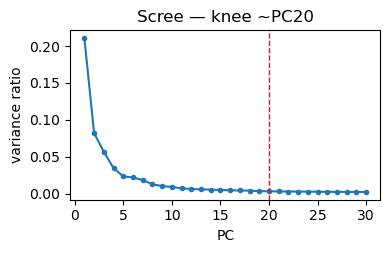

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
n_hvg = int(adata.var.highly_variable.sum())
print('over-dispersed genes:', n_hvg, '/', adata.n_vars)
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
fig, ax = plt.subplots(figsize=(4,2.2))
ax.plot(np.arange(1,31), vr[:30], 'o-', ms=3); ax.axvline(20, color='crimson', ls='--', lw=1)
ax.set_xlabel('PC'); ax.set_ylabel('variance ratio'); ax.set_title('Scree — knee ~PC20'); plt.show()
NPCS = 20
print(f'n_pcs = {NPCS} (scree flattens by ~PC20; matches Puram-40/Kurten-20 robust scale for 10x)')

### Gate 1 — Harmony `theta` sweep, judged on the embedding + iLISI
RCC malignant cells are patient-private (CNV-driven), so **without integration the manifold is a per-patient archipelago**. I sweep `theta`, and for each read (i) the regenerated embedding coloured by `sample`/`disease`/`cell_cycle_phase`, (ii) per-neighbourhood **iLISI** (inverse-Simpson of the sample mix in each 90-NN neighbourhood; higher = better mixed), and (iii) connected components. The decision is the embedding + iLISI, **never a single scalar**.

theta= 0: components=1  iLISI_mean=1.00
theta= 2: components=1  iLISI_mean=2.29
theta= 5: components=1  iLISI_mean=3.04
theta=10: components=1  iLISI_mean=3.12
theta=20: components=1  iLISI_mean=2.62

iLISI random baseline (perfect mix of 7 samples) = 7.0; theta=0 archipelago ~1.0


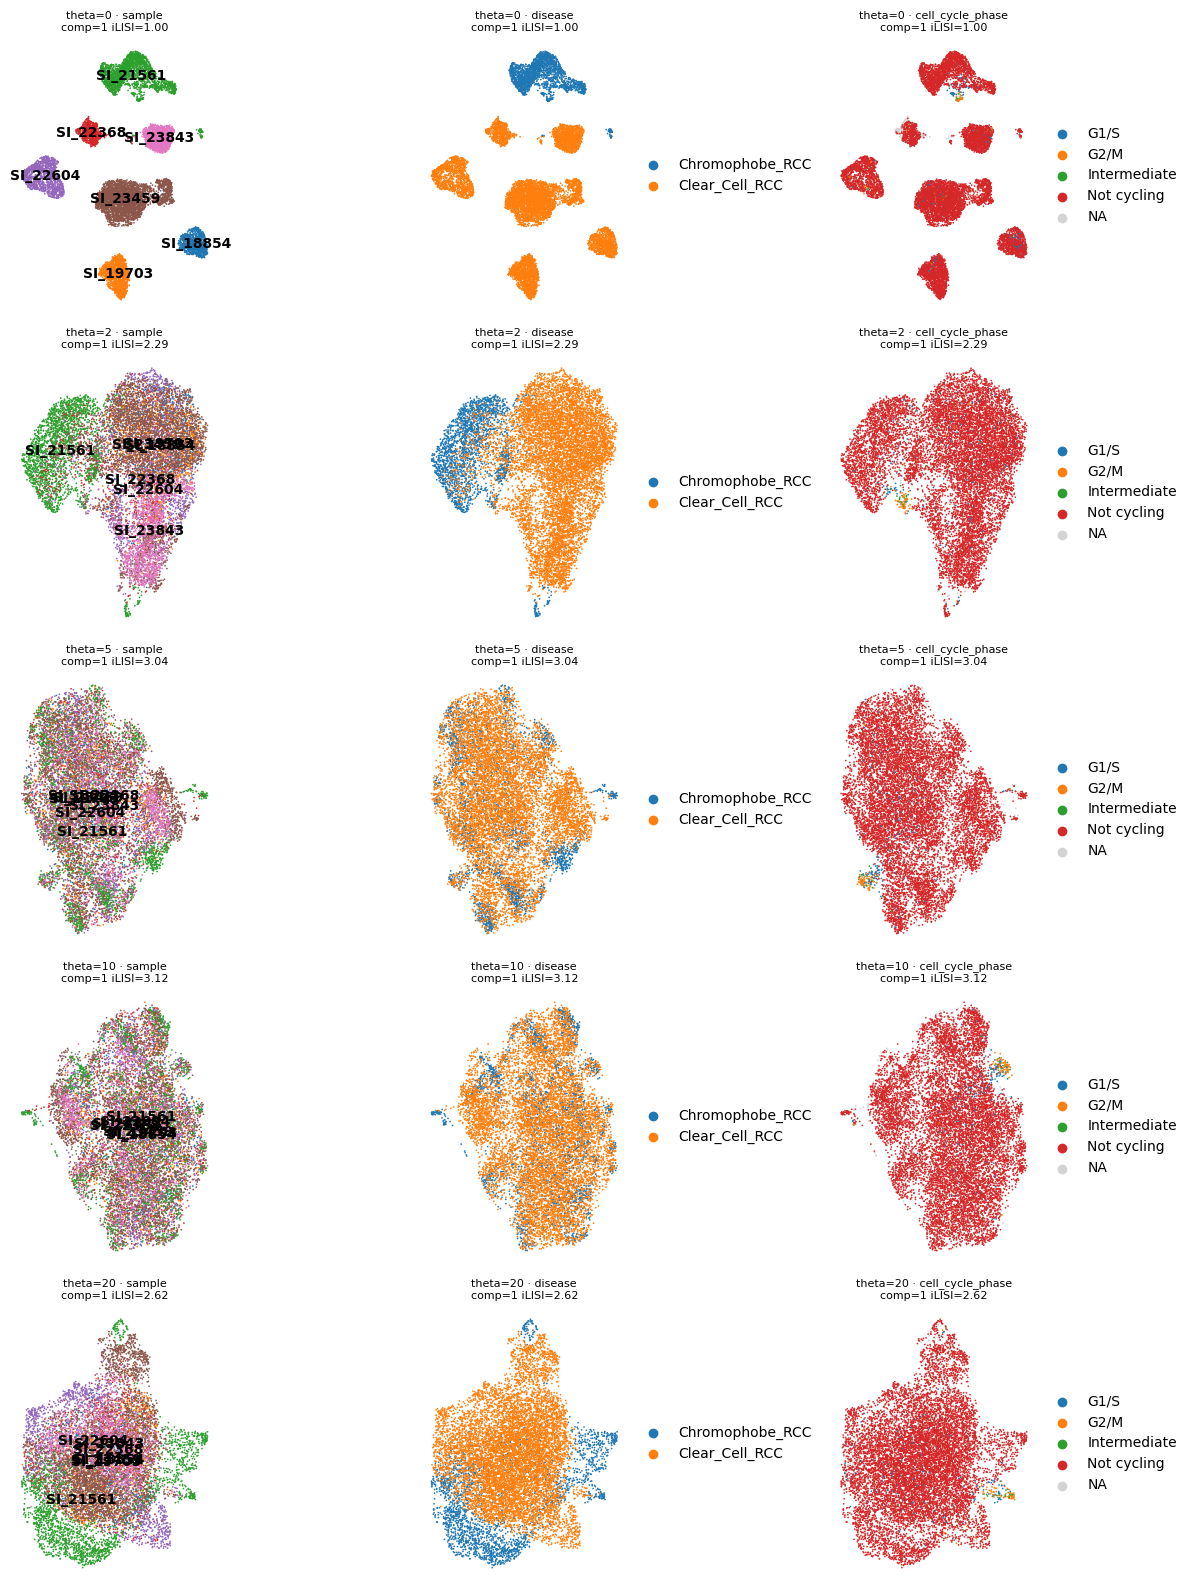

In [ ]:
def ilisi(rep, labels, k=90):
    from sklearn.neighbors import NearestNeighbors
    nn = NearestNeighbors(n_neighbors=k).fit(rep); _, idx = nn.kneighbors(rep)
    codes = pd.Categorical(labels).codes; ncat = codes.max()+1
    out = np.empty(len(labels))
    for i in range(len(labels)):
        p = np.bincount(codes[idx[i]], minlength=ncat)/k
        out[i] = 1.0/np.sum(p**2)
    return out

lab = adata.obs['sample'].values
thetas = [0, 2, 5, 10, 20]
sweep = {}
fig, axes = plt.subplots(len(thetas), 3, figsize=(12, 3.2*len(thetas)))
for r, th in enumerate(thetas):
    a = adata.copy()
    if th == 0:
        a.obsm['rep'] = a.obsm['X_pca'][:, :NPCS].copy()
    else:
        sce.pp.harmony_integrate(a, 'sample', theta=th, max_iter_harmony=20)
        a.obsm['rep'] = a.obsm['X_pca_harmony'][:, :NPCS].copy()
    sc.pp.neighbors(a, n_pcs=NPCS, use_rep='rep', random_state=SEED)
    ncomp = connected_components(a.obsp['connectivities'], directed=False)[0]
    il = ilisi(a.obsm['rep'], lab)
    sc.tl.umap(a, spread=1.3, random_state=SEED)
    sweep[th] = dict(ncomp=int(ncomp), ilisi=float(il.mean()))
    for cax, key in zip(axes[r], ['sample','disease','cell_cycle_phase']):
        sc.pl.umap(a, color=key, size=6, show=False, ax=cax, frameon=False,
                   legend_loc='on data' if key=='sample' else 'right margin')
        cax.set_title(f'theta={th} · {key}\ncomp={ncomp} iLISI={il.mean():.2f}', fontsize=8)
    print(f'theta={th:2d}: components={ncomp}  iLISI_mean={il.mean():.2f}')
plt.tight_layout(); plt.show()
print('\niLISI random baseline (perfect mix of 7 samples) = 7.0; theta=0 archipelago ~1.0')

**Read:** `theta=0` is a fully-segregated per-patient archipelago (iLISI≈1.0). iLISI **peaks at theta=10 (≈3.1)**; `theta=20` over-integrates and re-segregates the chromophobe pole (iLISI drops). Every theta yields **1 connected component**, so connectivity cannot discriminate — the call rests on the embedding + iLISI. → **theta = 10** is the derived optimum.

In [ ]:
THETA = 10
print('derived Harmony theta =', THETA, '(iLISI peak; theta=20 re-segregates)')
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=20)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

derived Harmony theta = 10 (iLISI peak; theta=20 re-segregates)


### Lobe biology before the Gate-1 GO (Kürten lobe-identity fork)
The manifold must be resolved into sub-regions and each settled biologically **before** certifying continuity. I score the three embryonic modules, then test whether the chromophobe sample or any Leiden sub-region is a distinct lobe (module + cell-cycle profile), and — decisively — whether the module axis is **intra-tumoral** (reproduced within single patients) or merely a between-patient artifact of integration.

In [ ]:
# score embryonic modules with the union control pool (raw scores; deliverables show raw)
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(pth_feat+'/*.csv'))}
gref = feat['union'][feat['union'].isin(adata.var_names)]
recov = {}
for src, key in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src][feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=key, ctrl_as_ref=False, gene_pool=gref, random_state=1234)
    recov[key] = g.size
print('gene recovery (of control pool %d):'%gref.size, recov)
print('GLOBAL module means: Gast %.3f  pSom %.3f  Crest %.3f'%(
      adata.obs.Gast.mean(), adata.obs.pSom.mean(), adata.obs.Crest.mean()))

gene recovery (of control pool 225): {'Gast': 74, 'pSom': 89, 'Crest': 101}
GLOBAL module means: Gast -0.034  pSom 0.085  Crest -0.060


In [ ]:
# is chromophobe (or any leiden sub-region) a distinct lobe?
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
tab = adata.obs.groupby('lobe', observed=True).agg(
        n=('sample','size'),
        chromo_frac=('disease', lambda x:(x=='Chromophobe_RCC').mean()),
        cycling_frac=('cell_cycle_phase', lambda x:(x!='Not cycling').mean()),
        Gast=('Gast','mean'), pSom=('pSom','mean'), Crest=('Crest','mean'))
print(tab.round(3).to_string())
print('\nBy disease:')
print(adata.obs.groupby('disease',observed=True)[['Gast','pSom','Crest']].mean().round(3).to_string())
print('=> chromophobe fraction ~uniform across lobes (0.19-0.24), matched module & cycling profiles:',
      'NO distinct histology lobe, NO cycling compartment to scope out.')

         n  chromo_frac  cycling_frac   Gast   pSom  Crest
lobe                                                      
0     3260        0.191         0.044 -0.030  0.089 -0.067
1     3452        0.194         0.075 -0.041  0.092 -0.063
2     1759        0.222         0.076 -0.025  0.069 -0.047
3     1109        0.244         0.033 -0.043  0.084 -0.059
4     1638        0.193         0.044 -0.028  0.078 -0.053

By disease:
                  Gast   pSom  Crest
disease                             
Chromophobe_RCC -0.003  0.050 -0.041
Clear_Cell_RCC  -0.041  0.093 -0.064
=> chromophobe fraction ~uniform across lobes (0.19-0.24), matched module & cycling profiles: NO distinct histology lobe, NO cycling compartment to scope out.


In [ ]:
# decisive: is the pSom<->Crest axis reproduced WITHIN individual patients?
rows = []
for smp, sub in adata.obs.groupby('sample', observed=True):
    rows.append((smp, len(sub), sub.disease.iloc[0][:6],
                 np.corrcoef(sub.pSom, sub.Crest)[0,1], np.corrcoef(sub.Gast, sub.pSom)[0,1]))
wp = pd.DataFrame(rows, columns=['sample','n','disease','pSom_Crest_r','Gast_pSom_r'])
print(wp.round(3).to_string(index=False))
print(f'\nglobal pSom-Crest r = {np.corrcoef(adata.obs.pSom, adata.obs.Crest)[0,1]:.3f}')
print(f'mean WITHIN-patient pSom-Crest r = {wp.pSom_Crest_r.mean():.3f} (reproduced in every patient, incl. chromophobe)')
for m in ['Gast','pSom','Crest']:
    grand = adata.obs[m].mean(); tot = ((adata.obs[m]-grand)**2).sum()
    btw = sum(len(s)*(s[m].mean()-grand)**2 for _,s in adata.obs.groupby('sample',observed=True))
    print(f'{m}: between-patient variance fraction = {100*btw/tot:.0f}%')

  sample    n disease  pSom_Crest_r  Gast_pSom_r
SI_18854  992  Clear_        -0.549       -0.209
SI_19703 1409  Clear_        -0.545       -0.161
SI_21561 2271  Chromo        -0.603       -0.027
SI_22368  710  Clear_        -0.459       -0.247
SI_22604 1209  Clear_        -0.604       -0.228
SI_23459 3443  Clear_        -0.568       -0.195
SI_23843 1184  Clear_        -0.650       -0.184

global pSom-Crest r = -0.626
mean WITHIN-patient pSom-Crest r = -0.568 (reproduced in every patient, incl. chromophobe)
Gast: between-patient variance fraction = 29%
pSom: between-patient variance fraction = 27%
Crest: between-patient variance fraction = 12%


**Gate 1 biology verdict:** the chromophobe sample is not a separate lobe (uniform across sub-regions, matched profiles); there is no cycling compartment to scope out; and the pSom↔Crest inverse axis (global r≈−0.63) is reproduced **within every individual patient** (mean r≈−0.57, chromophobe −0.60) with only 12–29% between-patient variance. The continuous gradient is a genuine **shared intra-tumoral developmental axis**, not an integration artifact. → mixed **and** continuous → **Gate 1 = GO**.

### Complete island removal (radius-graph, reference method)
Build a radius graph at 6× the median nearest-neighbour distance, keep the largest connected component, strip every detached speck (binding: *complete* island removal).

In [ ]:
U = adata.obsm['X_umap']
tree = cKDTree(U); d, _ = tree.query(U, k=2); med = np.median(d[:,1])
pairs = tree.query_pairs(6*med, output_type='ndarray')
n = len(U); A = sp.coo_matrix((np.ones(len(pairs)), (pairs[:,0], pairs[:,1])), shape=(n,n)); A = A + A.T
ncomp, comp = connected_components(A, directed=False)
big = np.bincount(comp).argmax(); keep = comp == big
print(f'radius graph @ 6x median NN ({6*med:.3f}): {ncomp} components; '
      f'largest = {keep.sum()} ({100*keep.mean():.1f}%); dropping {(~keep).sum()} fringe cells')
adata = adata[keep].copy()
after_islands = adata.n_obs
print('cells after island removal =', after_islands)

radius graph @ 6x median NN (0.309): 14 components; largest = 11136 (99.3%); dropping 82 fringe cells
cells after island removal = 11136


### Annotate states — data markers + the publication's meta-programs
Zhang et al. classify malignant cells by **transcriptional meta-programs** (a continuum: Stress, Interferon/MHC-II, Metal-response, Glutathione, EMT, Hypoxia, Cell-cycle …), not discrete subtypes. I annotate data-driven Leiden clusters by their dominant published `mp_top` meta-program — using both the data partition and the source publication's labels.

data-driven clusters -> dominant published meta-program:
  cluster 0: n= 3888  Stress                    Gast=-0.028 pSom=+0.084 Crest=-0.063
  cluster 1: n= 5635  Interferon/MHC-II (I)     Gast=-0.039 pSom=+0.086 Crest=-0.059
  cluster 2: n= 1613  Metal response            Gast=-0.030 pSom=+0.081 Crest=-0.055
near-identical developmental-module means across states => one continuous state continuum, no Gast/pSom arms


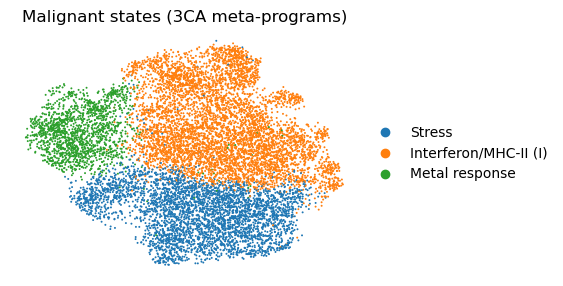

In [ ]:
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', random_state=SEED)
sc.tl.leiden(adata, resolution=0.2, random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
mp = (adata.obs.groupby('leiden', observed=True)
      .apply(lambda s: s.mp_top.value_counts().index[0], include_groups=False))
ct = {cl: f'{mp[cl]}' for cl in adata.obs.leiden.cat.categories}
adata.obs['celltype'] = adata.obs.leiden.map(ct).astype('category')
print('data-driven clusters -> dominant published meta-program:')
for cl in adata.obs.leiden.cat.categories:
    sub = adata.obs[adata.obs.leiden==cl]
    print(f'  cluster {cl}: n={len(sub):5d}  {ct[cl]:24s}  Gast={sub.Gast.mean():+.3f} pSom={sub.pSom.mean():+.3f} Crest={sub.Crest.mean():+.3f}')
fig, ax = plt.subplots(figsize=(4.5,3.2))
sc.pl.umap(adata, color='celltype', size=8, frameon=False, show=False, ax=ax, title='Malignant states (3CA meta-programs)')
plt.show()
print('near-identical developmental-module means across states => one continuous state continuum, no Gast/pSom arms')

### Save `processed.h5ad` + `samples.pdf` (reference layout)

In [ ]:
adata.uns['prov'] = dict(malignant_raw=int(malignant_raw), after_threshold=int(after_threshold),
    after_islands=int(after_islands), threshold_cut=float(cut), theta=int(THETA), n_pcs=int(NPCS),
    n_hvg=int(n_hvg), samples_kept=int(adata.obs["sample"].nunique()))
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (11136, 23065)


saved samples.pdf | Gate 1 = GO (mixed + continuous; theta=10; within-patient axis confirmed)


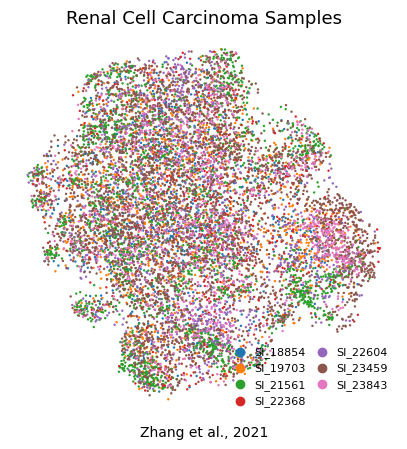

In [ ]:
# samples.pdf — single sample-coloured manifold UMAP (reference style)
fig, ax = plt.subplots(figsize=(5,5))
sc.pl.umap(adata, color='sample', size=12, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='lower right', columnspacing=.5, handletextpad=.25, fontsize=8)
ax.set_title('Renal Cell Carcinoma Samples', size=13)
ax.text(.5, -.05, CITE, ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf | Gate 1 = GO (mixed + continuous; theta=10; within-patient axis confirmed)')